# 02 — Analyse des signaux de l'accéléromètre

**Projet 5 — Analyse des mouvements avec un accéléromètre**

# Outils

Les fonctions sont écrites ici une seule fois, puis appelées dans chaque situation.

## Bloc 1 : charger les données

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DOSSIER_RAW = Path("../data/raw")   # données brutes : on les LIT, on ne les modifie jamais
DOSSIER_FIG = Path("../figures")    # graphiques enregistrés (images PNG)
DOSSIER_FIG.mkdir(exist_ok=True)    # crée le dossier s'il n'existe pas encore
FE_HZ = 100                         # fréquence d'échantillonnage (Hz)


def charger(situation):
    """Charge les 3 répétitions d'une situation. Renvoie {1: tableau, 2: tableau, 3: tableau}."""
    essais = {}
    for rep in [1, 2, 3]:
        df = pd.read_csv(DOSSIER_RAW / f"{situation}_rep{rep}.csv")
        print(f"Répétition {rep} : {len(df)} échantillons, durée = {df['t_s'].iloc[-1]:.2f} s")
        essais[rep] = df
    return essais

## Bloc 2 : tracer les trois axes

In [4]:
def tracer_axes(essais, titre, nom_fichier):
    """Trace X, Y, Z (une ligne par axe) pour les 3 répétitions (une colonne par répétition)
    et enregistre le graphique dans figures/<nom_fichier>.png."""
    axes_capteur = [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]

    # sharex : même échelle de temps partout ; sharey="row" : même échelle sur une ligne,
    # pour pouvoir comparer les 3 répétitions d'un même axe.
    fig, grille = plt.subplots(3, 3, figsize=(13, 7.5), sharex=True, sharey="row")

    for ligne, (colonne, nom) in enumerate(axes_capteur):
        for col, rep in enumerate([1, 2, 3]):
            case = grille[ligne, col]
            case.plot(essais[rep]["t_s"], essais[rep][colonne], color="#2a78d6", linewidth=0.8)
            case.set_title(f"Axe {nom}, répétition {rep}", fontsize=10)
            case.grid(alpha=0.3)

    for case in grille[:, 0]:
        case.set_ylabel("Accélération (g)")
    for case in grille[-1, :]:
        case.set_xlabel("Temps (s)")

    fig.suptitle(titre)
    fig.tight_layout()
    fig.savefig(DOSSIER_FIG / f"{nom_fichier}.png", dpi=150)   # avant plt.show()
    plt.show()

## Bloc 3 : calculer et tracer la norme

In [5]:
def ajouter_norme(essais):
    """Ajoute la colonne norme_g = racine(ax² + ay² + az²) à chaque répétition.
    La colonne est ajoutée en mémoire seulement : les fichiers CSV ne changent pas."""
    for df in essais.values():
        df["norme_g"] = np.sqrt(df["ax_g"]**2 + df["ay_g"]**2 + df["az_g"]**2)


def tracer_norme(essais, titre, nom_fichier):
    """Trace la norme des 3 répétitions (une colonne par répétition)
    et enregistre le graphique dans figures/<nom_fichier>.png."""
    fig, grille = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True, sharey=True)

    for case, rep in zip(grille, [1, 2, 3]):
        case.plot(essais[rep]["t_s"], essais[rep]["norme_g"], color="#2a78d6",
                  linewidth=0.8, label="Norme |a|")
        case.axhline(1, color="#52514e", linestyle="--", linewidth=1, label="1 g (gravité)")
        case.set_title(f"Répétition {rep}", fontsize=10)
        case.set_xlabel("Temps (s)")
        case.grid(alpha=0.3)

    grille[0].set_ylabel("Accélération (g)")
    fig.suptitle(titre)
    fig.legend(*grille[0].get_legend_handles_labels(), loc="upper right", ncol=2, fontsize=9)
    fig.tight_layout()
    fig.savefig(DOSSIER_FIG / f"{nom_fichier}.png", dpi=150)
    plt.show()

## Bloc 4 : calculer et tracer le spectre

In [6]:
def spectre(x):
    """Spectre d'amplitude d'un signal x. Renvoie (fréquences en Hz, amplitudes dans l'unité de x)."""
    N = len(x)
    x = np.asarray(x) - np.mean(x)                  # on enlève la moyenne (fréquence 0 Hz)
    frequences = np.fft.rfftfreq(N, d=1 / FE_HZ)    # de 0 à Fe/2 = 50 Hz
    amplitudes = 2 / N * np.abs(np.fft.rfft(x))     # 2/N : un sinus d'amplitude A donne un pic A
    return frequences, amplitudes


def tracer_spectre(essais, titre, nom_fichier, fmin=0, fmax=50):
    """Trace le spectre de X, Y, Z (une ligne par axe) pour les 3 répétitions (une colonne
    par répétition) et enregistre le graphique dans figures/<nom_fichier>.png.
    fmin, fmax : bande de fréquences affichée (Hz), pour zoomer."""
    axes_capteur = [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]
    fig, grille = plt.subplots(3, 3, figsize=(13, 7.5), sharex=True, sharey="row")

    for ligne, (colonne, nom) in enumerate(axes_capteur):
        for col, rep in enumerate([1, 2, 3]):
            f, A = spectre(essais[rep][colonne])
            bande = (f >= fmin) & (f <= fmax)
            case = grille[ligne, col]
            case.plot(f[bande], A[bande] * 1000, color="#2a78d6", linewidth=0.8)   # g -> mg
            case.set_title(f"Axe {nom}, répétition {rep}", fontsize=10)
            case.grid(alpha=0.3)

    for case in grille[:, 0]:
        case.set_ylabel("Amplitude (mg)")
    for case in grille[-1, :]:
        case.set_xlabel("Fréquence (Hz)")

    fig.suptitle(titre)
    fig.tight_layout()
    fig.savefig(DOSSIER_FIG / f"{nom_fichier}.png", dpi=150)
    plt.show()

## Bloc 5 : moyenne glissante

In [7]:
def moyenne_glissante(x, M):
    """Remplace chaque point par la moyenne des M points centrés sur lui (M impair).
    Aux deux bords, il manque des voisins : le résultat y est vide (NaN)."""
    return x.rolling(window=M, center=True).mean()


def tracer_moyenne_glissante(essais, rep, fenetres, titre, nom_fichier):
    """Compare avant/après pour une répétition : une ligne par axe, une colonne par fenêtre M.
    Enregistre le graphique dans figures/<nom_fichier>.png."""
    axes_capteur = [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]
    df = essais[rep]
    fig, grille = plt.subplots(3, len(fenetres), figsize=(13, 7.5), sharex=True, sharey="row")

    for ligne, (colonne, nom) in enumerate(axes_capteur):
        for col, M in enumerate(fenetres):
            case = grille[ligne, col]
            case.plot(df["t_s"], df[colonne], color="#b8b6ae", linewidth=0.7, label="Signal brut")
            case.plot(df["t_s"], moyenne_glissante(df[colonne], M), color="#2a78d6",
                      linewidth=1.2, label="Signal filtré")
            case.set_title(f"Axe {nom}, fenêtre M = {M}", fontsize=10)
            case.grid(alpha=0.3)

    for case in grille[:, 0]:
        case.set_ylabel("Accélération (g)")
    for case in grille[-1, :]:
        case.set_xlabel("Temps (s)")

    fig.suptitle(titre)
    fig.legend(*grille[0, 0].get_legend_handles_labels(), loc="upper right", ncol=2, fontsize=9)
    fig.tight_layout()
    fig.savefig(DOSSIER_FIG / f"{nom_fichier}.png", dpi=150)
    plt.show()


def tableau_moyenne_glissante(essais, fenetres):
    """Tableau : moyenne (g) et écart-type global (mg) de chaque axe, avant et après filtrage."""
    lignes = []
    for rep, df in essais.items():
        for colonne, nom in [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]:
            ligne = {"Répétition": rep, "Axe": nom,
                     "Moyenne brute (g)": round(df[colonne].mean(), 4),
                     "σ brut (mg)": round(df[colonne].std() * 1000, 2)}
            for M in fenetres:
                ligne[f"σ M={M} (mg)"] = round(moyenne_glissante(df[colonne], M).std() * 1000, 2)
            lignes.append(ligne)
    return pd.DataFrame(lignes)

## Bloc 6 : passe-bas de Butterworth

In [8]:
from scipy.signal import butter, sosfiltfilt

ORDRE = 4   # ordre du filtre (fixé)


def passe_bas(x, fc):
    """Passe-bas de Butterworth d'ordre ORDRE et de fréquence de coupure fc (Hz).
    Appliqué à l'endroit puis à l'envers : pas de retard, mais le gain agit deux fois
    (à fc il reste 0,707 x 0,707 = 50 % de l'amplitude)."""
    coefficients = butter(ORDRE, fc, btype="lowpass", fs=FE_HZ, output="sos")
    return sosfiltfilt(coefficients, x)


def tracer_passe_bas(essais, rep, coupures, titre, nom_fichier):
    """Compare avant/après pour une répétition : une ligne par axe, une colonne par coupure fc.
    Enregistre le graphique dans figures/<nom_fichier>.png."""
    axes_capteur = [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]
    df = essais[rep]
    fig, grille = plt.subplots(3, len(coupures), figsize=(13, 7.5), sharex=True, sharey="row")

    for ligne, (colonne, nom) in enumerate(axes_capteur):
        for col, fc in enumerate(coupures):
            case = grille[ligne, col]
            case.plot(df["t_s"], df[colonne], color="#b8b6ae", linewidth=0.7, label="Signal brut")
            case.plot(df["t_s"], passe_bas(df[colonne], fc), color="#2a78d6",
                      linewidth=1.2, label="Signal filtré")
            case.set_title(f"Axe {nom}, fc = {fc} Hz", fontsize=10)
            case.grid(alpha=0.3)

    for case in grille[:, 0]:
        case.set_ylabel("Accélération (g)")
    for case in grille[-1, :]:
        case.set_xlabel("Temps (s)")

    fig.suptitle(titre)
    fig.legend(*grille[0, 0].get_legend_handles_labels(), loc="upper right", ncol=2, fontsize=9)
    fig.tight_layout()
    fig.savefig(DOSSIER_FIG / f"{nom_fichier}.png", dpi=150)
    plt.show()


def tableau_passe_bas(essais, coupures):
    """Tableau : écart-type global (mg) de chaque axe, avant et après filtrage."""
    lignes = []
    for rep, df in essais.items():
        for colonne, nom in [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]:
            ligne = {"Répétition": rep, "Axe": nom,
                     "σ brut (mg)": round(df[colonne].std() * 1000, 2)}
            for fc in coupures:
                ligne[f"σ fc={fc} Hz (mg)"] = round(np.std(passe_bas(df[colonne], fc), ddof=1) * 1000, 2)
            lignes.append(ligne)
    return pd.DataFrame(lignes)

## Bloc 7 : comparer les deux filtres

In [9]:
def comparer_filtres(essais, debut=0, fin=15):
    """Tableau : écart-type (mg) brut et après chaque filtre, à coupure comparable
    (M = 11 et fc = 4 Hz ; M = 21 et fc = 2 Hz).
    L'écart-type est calculé entre les instants debut et fin (s) : par défaut tout le signal.
    Avec du mouvement, on choisit une phase calme pour mesurer le bruit et non le mouvement."""
    lignes = []
    for rep, df in essais.items():
        calme = (df["t_s"] >= debut) & (df["t_s"] <= fin)   # instants pris en compte
        for colonne, nom in [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]:
            x = df[colonne]
            lignes.append({
                "Répétition": rep,
                "Axe": nom,
                "Brut": x[calme].std() * 1000,
                "Moy. glissante M=11": moyenne_glissante(x, 11)[calme].std() * 1000,
                "Butterworth fc=4 Hz": np.std(passe_bas(x, 4)[calme], ddof=1) * 1000,
                "Moy. glissante M=21": moyenne_glissante(x, 21)[calme].std() * 1000,
                "Butterworth fc=2 Hz": np.std(passe_bas(x, 2)[calme], ddof=1) * 1000,
            })
    return pd.DataFrame(lignes).round(2)

## Bloc 8 : comparer les filtres par la rugosité

Pour les situations sans phase calme, où l'écart-type mesurerait le mouvement.

In [10]:
def rugosite(x):
    """Écart-type (mg) de la différence entre deux mesures successives.
    Un mouvement lent change peu en 10 ms ; le bruit et les tremblements changent beaucoup."""
    return np.nanstd(np.diff(x)) * 1000


def comparer_rugosite(essais):
    """Tableau : rugosité (mg) brute et après chaque filtre, à coupure comparable."""
    lignes = []
    for rep, df in essais.items():
        for colonne, nom in [("ax_g", "X"), ("ay_g", "Y"), ("az_g", "Z")]:
            x = df[colonne]
            lignes.append({
                "Répétition": rep,
                "Axe": nom,
                "Brut": rugosite(x),
                "Moy. glissante M=11": rugosite(moyenne_glissante(x, 11)),
                "Butterworth fc=4 Hz": rugosite(passe_bas(x, 4)),
                "Moy. glissante M=21": rugosite(moyenne_glissante(x, 21)),
                "Butterworth fc=2 Hz": rugosite(passe_bas(x, 2)),
            })
    return pd.DataFrame(lignes).round(2)

# Situation 1 — Immobile

In [65]:
immobile = charger("immobile")
immobile[1].head()

Répétition 1 : 1500 échantillons, durée = 14.99 s
Répétition 2 : 1500 échantillons, durée = 14.99 s
Répétition 3 : 1500 échantillons, durée = 14.99 s


,t_us,t_s,ax_g,ay_g,az_g
0,143372611,0.000000,0.17529,-0.01367,1.02637
1,143382610,0.009999,0.17017,-0.01123,1.02124
2,143392612,0.020001,0.18018,-0.01392,1.02808
3,143402610,0.029999,0.18237,-0.01270,1.02881
4,143412611,0.040000,0.18115,-0.00806,1.01953


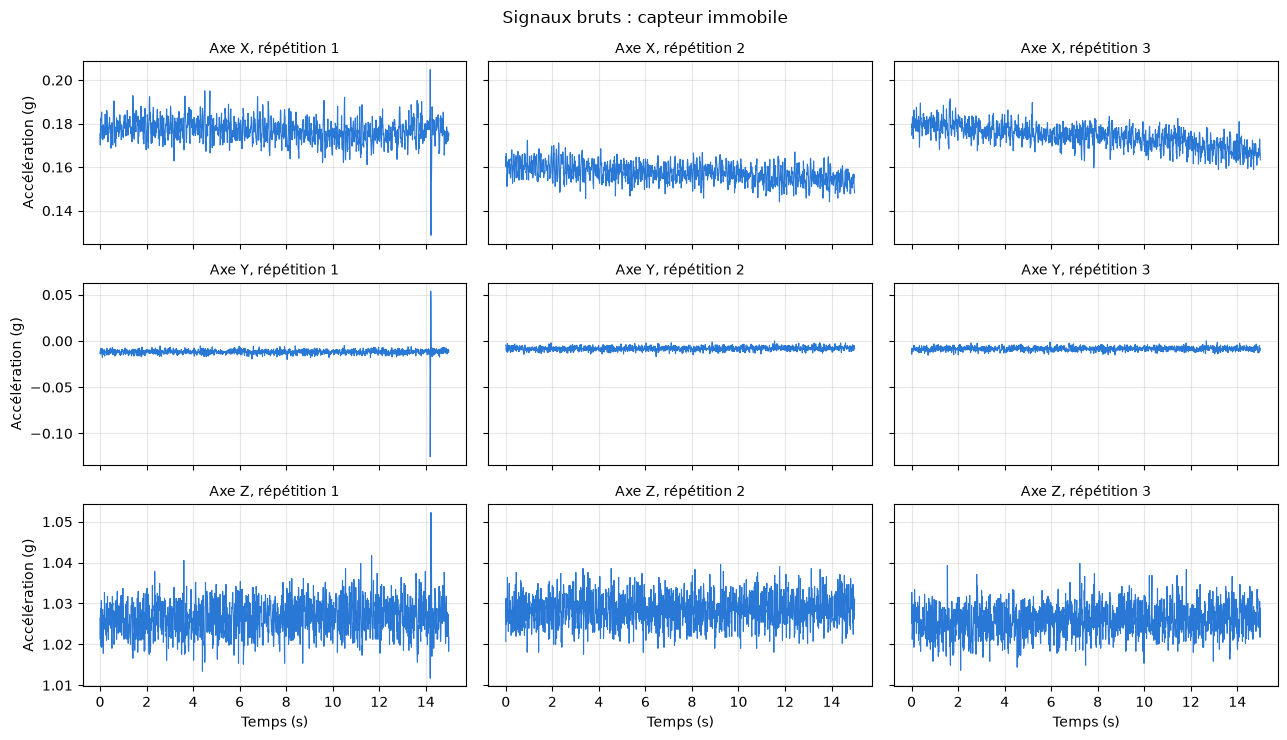

In [66]:
tracer_axes(immobile, "Signaux bruts : capteur immobile", "immobile_axes_bruts")

### Interprétation : capteur immobile, signaux bruts

**Valeurs moyennes.** Le capteur était posé avec l'axe Z vers le haut. Dans le cas idéal, on aurait X = 0 g, Y = 0 g et Z = 1 g, car Z porte seul la gravité. On mesure :

| | Répétition 1 | Répétition 2 | Répétition 3 |
|---|---|---|---|
| X (g) | 0,177 | 0,157 | 0,174 |
| Y (g) | -0,012 | -0,008 | -0,009 |
| Z (g) | 1,027 | 1,029 | 1,026 |

- **Y** est pratiquement nul, comme attendu.
- **X** n'est pas nul : le capteur était incliné d'environ 10° (arcsin 0,17), car il n'était pas parfaitement à plat sur la plaque d'essai.
- **Z** dépasse 1 g, alors qu'une inclinaison de 10° devrait donner environ 0,985 g. L'écart d'environ +0,04 g est un décalage (offset) propre au capteur.

**Bruit.** Le grésillement permanent est aléatoire et présent sur les trois axes. Son écart-type global est d'environ 2 mg sur Y (4,6 mg dans la répétition 1, à cause du choc), 4 à 5 mg sur X (dérive comprise) et 4 mg sur Z. Sur Y et Z, il s'agit essentiellement du bruit électronique du capteur. Sur X, les fluctuations sont en partie plus lentes : de petits mouvements dus à la fixation du capteur peuvent s'y ajouter.

**Perturbation.** Dans la répétition 1, un pic bref (environ 0,1 s) apparaît à t = 14,2 s sur les trois axes, surtout sur Y (de -0,125 à +0,054 g). Il provient probablement d'un choc sur la plaque d'essai ou sur la table.

**Dérive.** X diminue lentement au cours du temps, en restant positif : de 4 mg (répétition 1) à 12 mg (répétition 3) en 15 s. En même temps, Z augmente très légèrement (environ 1 à 2 mg), ce qui correspond à une rotation très lente du capteur, de l'ordre de 0,7° au maximum. L'hypothèse la plus probable est un léger relâchement de la fixation.

**Répétabilité.** Les trois répétitions concordent sur Y et Z. Sur X, la répétition 2 est décalée d'environ 0,02 g, soit environ 1° : la position du capteur a légèrement changé entre les essais.

## Norme : capteur immobile

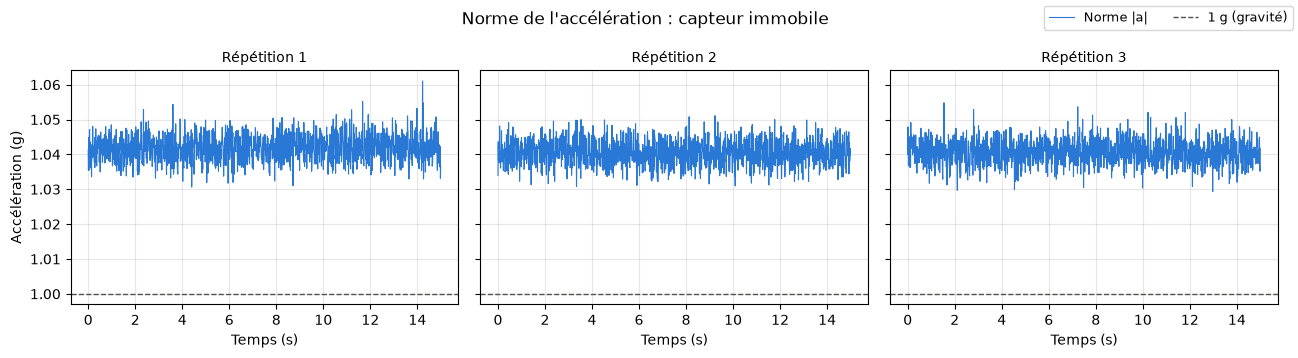

Répétition 1 : moyenne = 1.0418 g, écart-type = 3.72 mg
Répétition 2 : moyenne = 1.0405 g, écart-type = 3.53 mg
Répétition 3 : moyenne = 1.0406 g, écart-type = 3.50 mg


In [67]:
ajouter_norme(immobile)
tracer_norme(immobile, "Norme de l'accélération : capteur immobile", "immobile_norme_brute")

# Moyenne et écart-type de la norme pour chaque répétition
for rep, df in immobile.items():
    print(f"Répétition {rep} : moyenne = {df['norme_g'].mean():.4f} g, "
          f"écart-type = {df['norme_g'].std() * 1000:.2f} mg")

### Interprétation : capteur immobile, norme

**Valeur moyenne.** Au repos, la norme devrait valoir 1 g quelle que soit l'orientation du capteur, car une inclinaison répartit la gravité entre les axes sans modifier sa longueur totale. On mesure environ 1,041 g dans les trois répétitions. L'écart d'environ +0,04 g ne vient ni de l'inclinaison ni du bruit (le bruit fluctue autour de la moyenne sans la déplacer) : il vient du décalage (offset) de l'axe Z.

**Bruit.** L'écart-type de la norme, calculé sur les 15 s, est d'environ 3,5 à 3,7 mg : il est proche de celui de Z, qui porte presque toute la gravité.

**Répétabilité.** Le décalage de 0,02 g observé sur X dans la répétition 2 n'apparaît pas sur la norme : sa moyenne (1,0405 g) est pratiquement égale à celle de la répétition 3 (1,0406 g). Ce décalage correspond à un changement d'inclinaison : quand X diminue, Z augmente et compense.

**Dérive.** Pour la même raison, la dérive lente de X ne se voit pas sur la norme, qui varie de moins de 1 mg en 15 s (contre 4 à 12 mg pour X).

**Choc.** Le choc à 14,2 s (répétition 1) est très visible sur Y (-0,125 g) mais peu sur la norme. Les axes y interviennent au carré : 0,125² = 0,016, contre 1,012² = 1,024 pour Z. La gravité, portée par Z, masque donc une perturbation qui lui est perpendiculaire.

**Bilan.** La norme est insensible à l'orientation du capteur, mais elle ne suffit pas : il faut aussi regarder les trois axes séparément.

## Spectre : capteur immobile

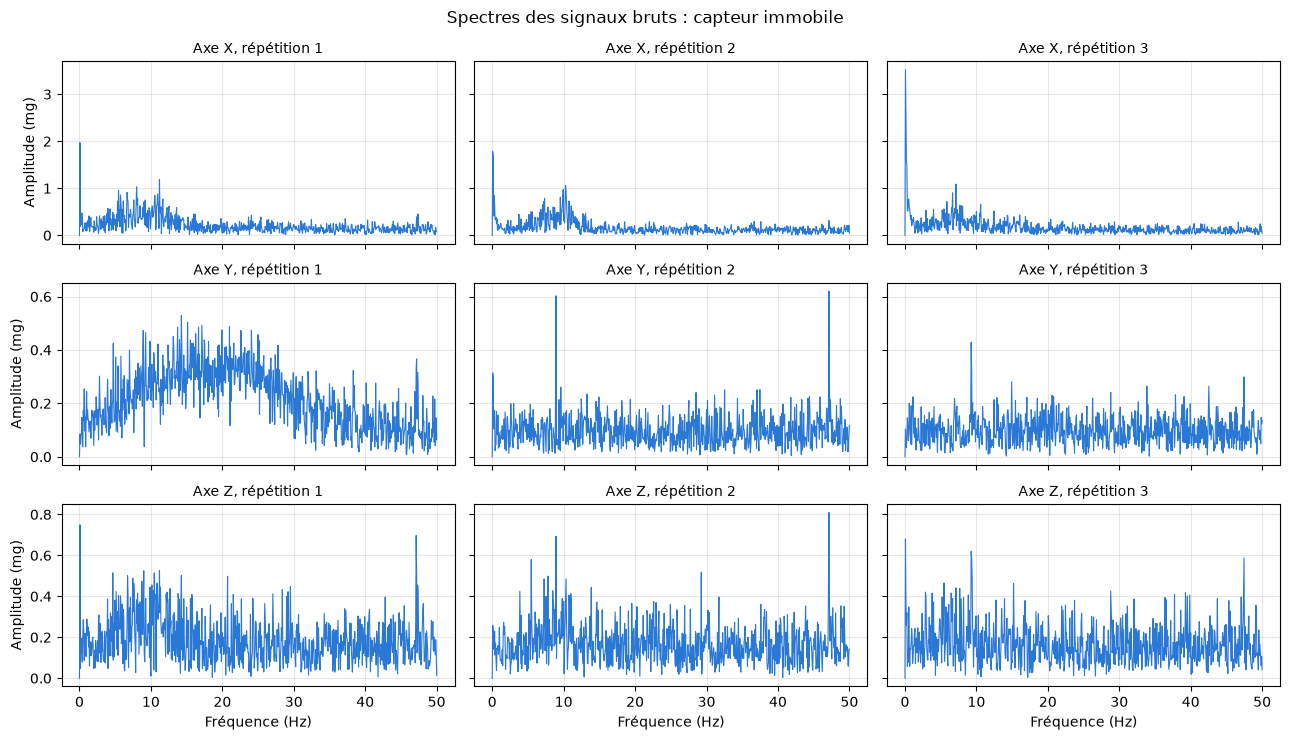

In [68]:
tracer_spectre(immobile, "Spectres des signaux bruts : capteur immobile", "immobile_spectre_brut")

### Interprétation : capteur immobile, spectres

**Très basses fréquences.** Sur X, le pic proche de 0 Hz (premier point du spectre, 0,067 Hz) correspond à une variation très lente : c'est la dérive observée sur le signal temporel. Il est plus grand dans la répétition 3 (3,5 mg), où la dérive est la plus forte (12 mg en 15 s).

**Bruit de fond.** Sur Y (répétitions 2 et 3), le spectre est à peu près plat de 0 à 50 Hz : aucune fréquence n'est privilégiée. C'est la signature d'un bruit blanc, cohérente avec le bruit électronique du capteur. Z présente un fond presque plat également.

**Effet du choc.** Le spectre de Y dans la répétition 1 est bombé entre 5 et 35 Hz environ, contrairement aux deux autres. Cette répétition contient le choc de 14,2 s : un événement très bref dans le temps s'étale sur une large bande de fréquences.

**Vibration mécanique.** X présente une bosse entre 5 et 12 Hz environ dans les trois répétitions. On la retrouve plus faiblement sur Z, et pas sur Y. Il s'agit probablement de petites oscillations du capteur autour de l'axe Y, dues à sa fixation imparfaite sur la plaque d'essai.

**Raies fines.** Des pics étroits apparaissent vers 9 Hz (répétitions 2 et 3) et vers 47 Hz. Leur origine n'est pas identifiée (vibration extérieure ou parasite électrique).

**Bilan.** Toutes les amplitudes restent inférieures à 4 mg : il n'y a pas de mouvement volontaire, seulement une dérive lente, de faibles vibrations et du bruit. Ces spectres servent de référence : ce qui dépassera nettement ce niveau dans les autres situations sera dû au mouvement.

## Moyenne glissante : capteur immobile

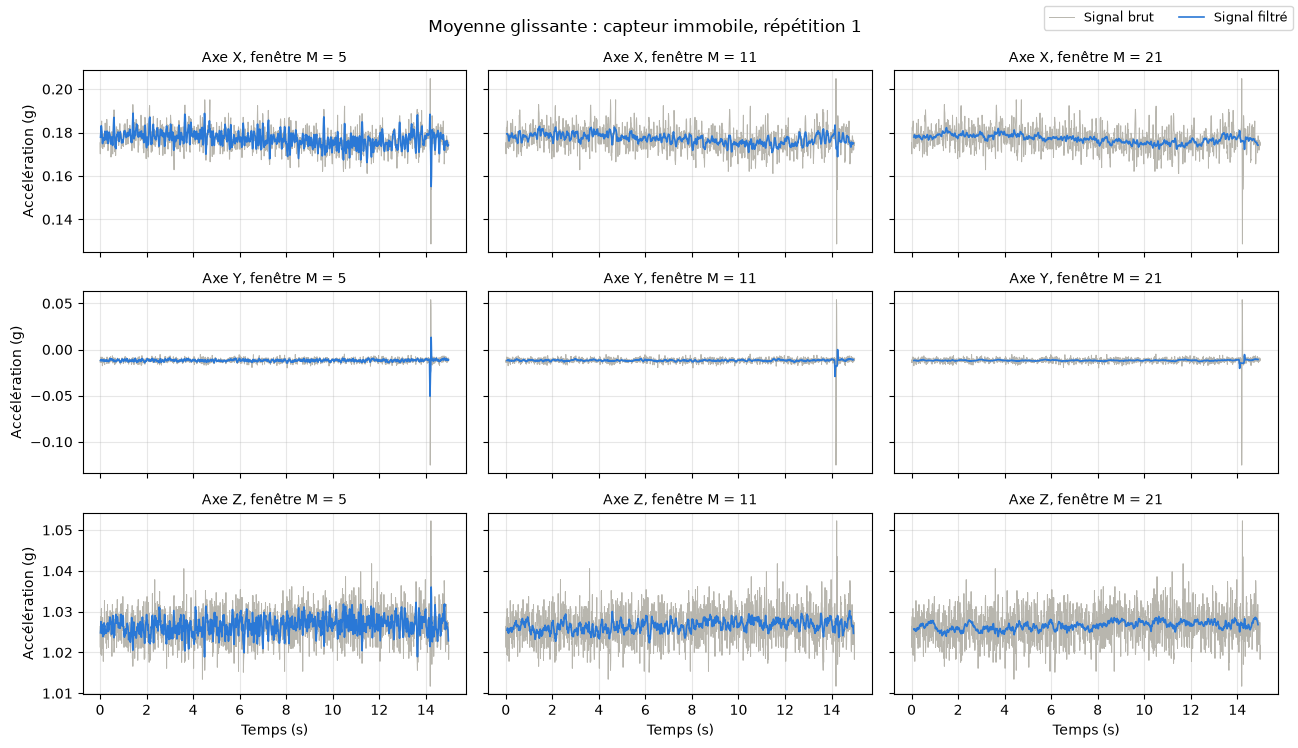

,Répétition,Axe,Moyenne brute (g),σ brut (mg),σ M=5 (mg),σ M=11 (mg),σ M=21 (mg)
0,1,X,0.1771,5.32,3.54,2.22,1.78
1,1,Y,-0.0118,4.63,1.91,1.04,0.66
2,1,Z,1.0265,4.17,2.15,1.30,0.94
3,2,X,0.1573,4.43,3.16,2.26,2.09
4,2,Y,-0.0082,2.21,1.02,0.67,0.51
5,2,Z,1.0285,3.74,1.79,1.02,0.70
6,3,X,0.1741,5.25,4.38,3.86,3.69
7,3,Y,-0.0085,2.15,0.96,0.63,0.46
8,3,Z,1.0259,3.73,1.90,1.27,0.95


In [69]:
FENETRES = [5, 11, 21]   # tailles de fenêtre testées (nombre de points)

tracer_moyenne_glissante(immobile, 1, FENETRES,
                         "Moyenne glissante : capteur immobile, répétition 1",
                         "immobile_rep1_moyenne_glissante")
tableau_moyenne_glissante(immobile, FENETRES)

### Interprétation : capteur immobile, moyenne glissante

**Paramètre testé.** La taille de la fenêtre M : 5, 11 et 21 points (0,05 s, 0,11 s et 0,21 s).

**Réduction du bruit.** Plus M augmente, plus l'écart-type diminue. Pour Y dans la répétition 2, il passe de 2,21 mg à 1,02, 0,67 puis 0,51 mg : il est divisé par 2,2, 3,3 et 4,3. Pour un bruit blanc, on attend une division par √M, soit 2,2, 3,3 et 4,6. L'accord est bon et confirme que le bruit de Y est pratiquement blanc.

**Limite : la dérive.** Sur X dans la répétition 3, l'écart-type diminue peu (de 5,25 à 3,69 mg avec M = 21). Ce qui reste est surtout la dérive lente, que la moyenne glissante conserve : elle n'atténue que les variations rapides.

**Effet sur le choc.** Le choc à 14,2 s (Y, répétition 1) est atténué mais ne disparaît pas : son minimum passe d'environ -0,125 g à -0,05, -0,03 puis -0,02 g. En contrepartie, il est étalé sur la durée de la fenêtre.

**Choix de la fenêtre.** Pour le capteur immobile, M = 21 réduit le plus le bruit, sans inconvénient puisqu'il n'y a pas de mouvement à conserver. Ce choix devra être vérifié sur les autres situations, où une fenêtre trop grande pourrait déformer le mouvement.

## Passe-bas de Butterworth : capteur immobile

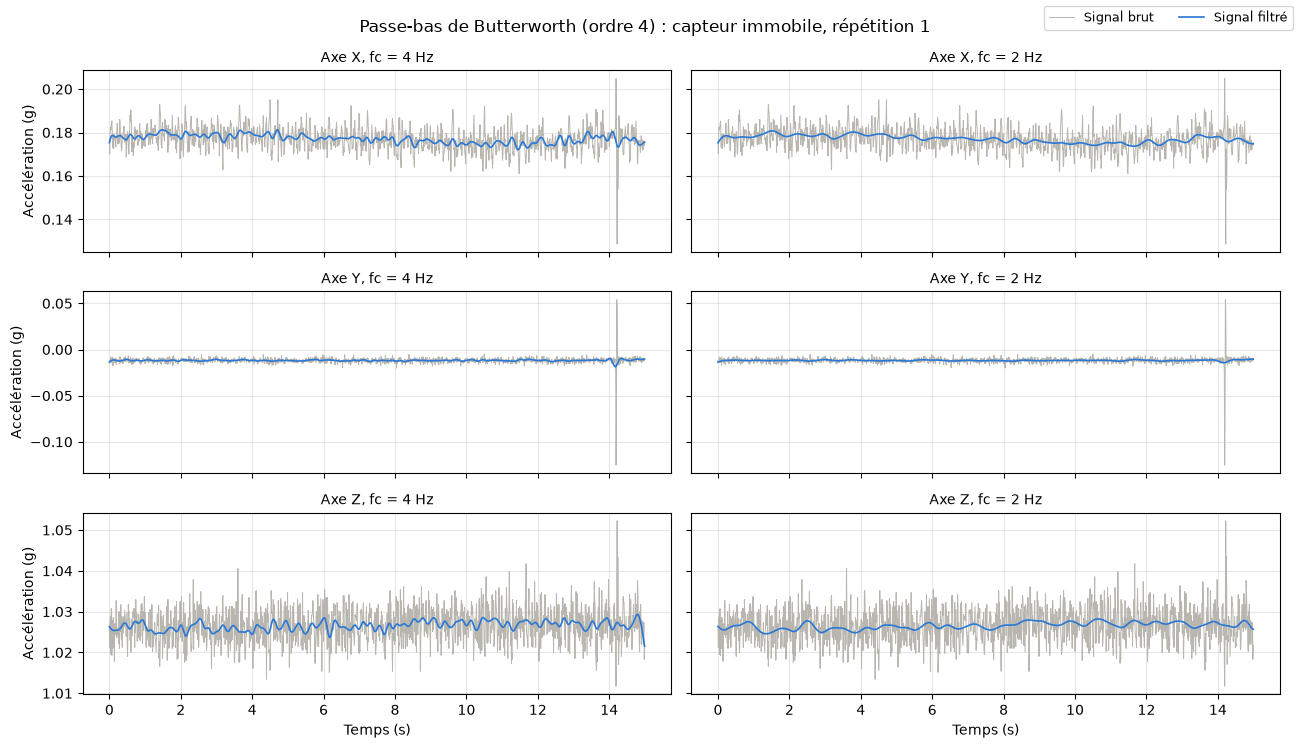

,Répétition,Axe,σ brut (mg),σ fc=4 Hz (mg),σ fc=2 Hz (mg)
0,1,X,5.32,1.90,1.64
1,1,Y,4.63,0.78,0.51
2,1,Z,4.17,1.08,0.82
3,2,X,4.43,2.19,2.12
4,2,Y,2.21,0.62,0.51
5,2,Z,3.74,0.89,0.74
6,3,X,5.25,3.80,3.71
7,3,Y,2.15,0.58,0.45
8,3,Z,3.73,1.13,0.86


In [70]:
COUPURES = [4, 2]   # fréquences de coupure testées (Hz)

tracer_passe_bas(immobile, 1, COUPURES,
                 "Passe-bas de Butterworth (ordre 4) : capteur immobile, répétition 1",
                 "immobile_rep1_passe_bas")
tableau_passe_bas(immobile, COUPURES)

### Interprétation : capteur immobile, passe-bas de Butterworth

**Paramètres.** Ordre 4 fixe, fréquence de coupure fc = 4 Hz puis 2 Hz.

**Réduction du bruit.** Quand fc diminue, le filtre laisse passer une bande de fréquences plus étroite, donc moins de bruit. Pour Y dans la répétition 2, l'écart-type passe de 2,21 mg à 0,62 mg (fc = 4 Hz) puis 0,51 mg (fc = 2 Hz).

**Limite : la dérive.** Sur X dans la répétition 3, l'écart-type reste à environ 3,7 à 3,8 mg pour les deux coupures. La dérive se situe près de 0 Hz, très en dessous de fc : le filtre la conserve.

**Effet sur le choc.** Le choc à 14,2 s (Y, répétition 1) est fortement atténué : son minimum passe d'environ -0,125 g à -0,019 g (fc = 4 Hz) et -0,014 g (fc = 2 Hz). Un choc bref contient beaucoup de hautes fréquences, que le filtre atténue. Il reste une petite ondulation étalée dans le temps.

**Effet de bord.** Sur Z (répétition 1, fc = 4 Hz), la courbe filtrée plonge juste avant 15 s. Ce n'est pas un mouvement : au bord, le filtre ne dispose plus des mesures suivantes et sa sortie s'aligne sur la dernière mesure brute, qui est ici un peu basse à cause du bruit. Les premiers et derniers instants du signal filtré ne sont donc pas à interpréter.

**Choix de fc.** Avec deux passages, le gain vaut 1 / (1 + (f/fc)^8). À 2,2 Hz, il est de 0,99 pour fc = 4 Hz, mais de 0,32 pour fc = 2 Hz. fc = 4 Hz est donc le choix le plus prudent pour ne pas déformer un mouvement ; il devra être vérifié sur les oscillations.

## Comparaison des deux filtres : capteur immobile

Écart-type global σ, en mg.

In [71]:
comparer_filtres(immobile)

,Répétition,Axe,Brut,Moy. glissante M=11,Butterworth fc=4 Hz,Moy. glissante M=21,Butterworth fc=2 Hz
0,1,X,5.32,2.22,1.90,1.78,1.64
1,1,Y,4.63,1.04,0.78,0.66,0.51
2,1,Z,4.17,1.30,1.08,0.94,0.82
3,2,X,4.43,2.26,2.19,2.09,2.12
4,2,Y,2.21,0.67,0.62,0.51,0.51
5,2,Z,3.74,1.02,0.89,0.70,0.74
6,3,X,5.25,3.86,3.80,3.69,3.71
7,3,Y,2.15,0.63,0.58,0.46,0.45
8,3,Z,3.73,1.27,1.13,0.95,0.86


### Interprétation : capteur immobile, comparaison des deux filtres

**Réduction du bruit.** À réglage comparable, les deux filtres donnent des écarts-types proches. Autour de 4 Hz, le Butterworth est légèrement meilleur dans les 9 cas. Autour de 2 Hz, les résultats sont partagés : l'un ou l'autre est devant selon l'axe et la répétition. Ces petits écarts ne suffisent pas à dire qu'un filtre est meilleur, car les coupures ne sont pas exactement égales : après deux passages, le Butterworth coupe un peu plus bas (3,6 Hz au lieu de 4,0 Hz pour M = 11 ; 1,8 Hz au lieu de 2,1 Hz pour M = 21).

**Forme du signal filtré.** La courbe du Butterworth est plus lisse. La moyenne glissante laisse encore passer une partie des fréquences au-dessus de sa coupure (pour M = 11, environ 22 % de l'amplitude vers 13 Hz), alors que le gain du Butterworth y est presque nul. C'est ce qui laisse de petites variations rapides sur la moyenne glissante.

**Avantages et limites.** La moyenne glissante est très simple, mais elle ne se règle que par une taille de fenêtre. Le Butterworth se règle directement en fréquence et sépare mieux le mouvement des vibrations. Aucun des deux ne supprime la dérive ni le décalage de Z.

**Bilan.** Sur un capteur immobile, les deux filtres sont presque équivalents. La différence se jugera sur les situations avec mouvement.

# Situation 2 — Inclinaison

In [72]:
inclinaison = charger("inclinaison")
inclinaison[1].head()

Répétition 1 : 1500 échantillons, durée = 14.99 s
Répétition 2 : 1500 échantillons, durée = 14.99 s
Répétition 3 : 1500 échantillons, durée = 14.99 s


,t_us,t_s,ax_g,ay_g,az_g
0,2160023611,0.000000,0.95898,-0.01123,-0.27661
1,2160033610,0.009999,0.96191,-0.00757,-0.27637
2,2160043612,0.020001,0.96118,-0.01074,-0.27295
3,2160053612,0.030001,0.96265,-0.01099,-0.27563
4,2160063611,0.040000,0.96436,-0.01099,-0.27124


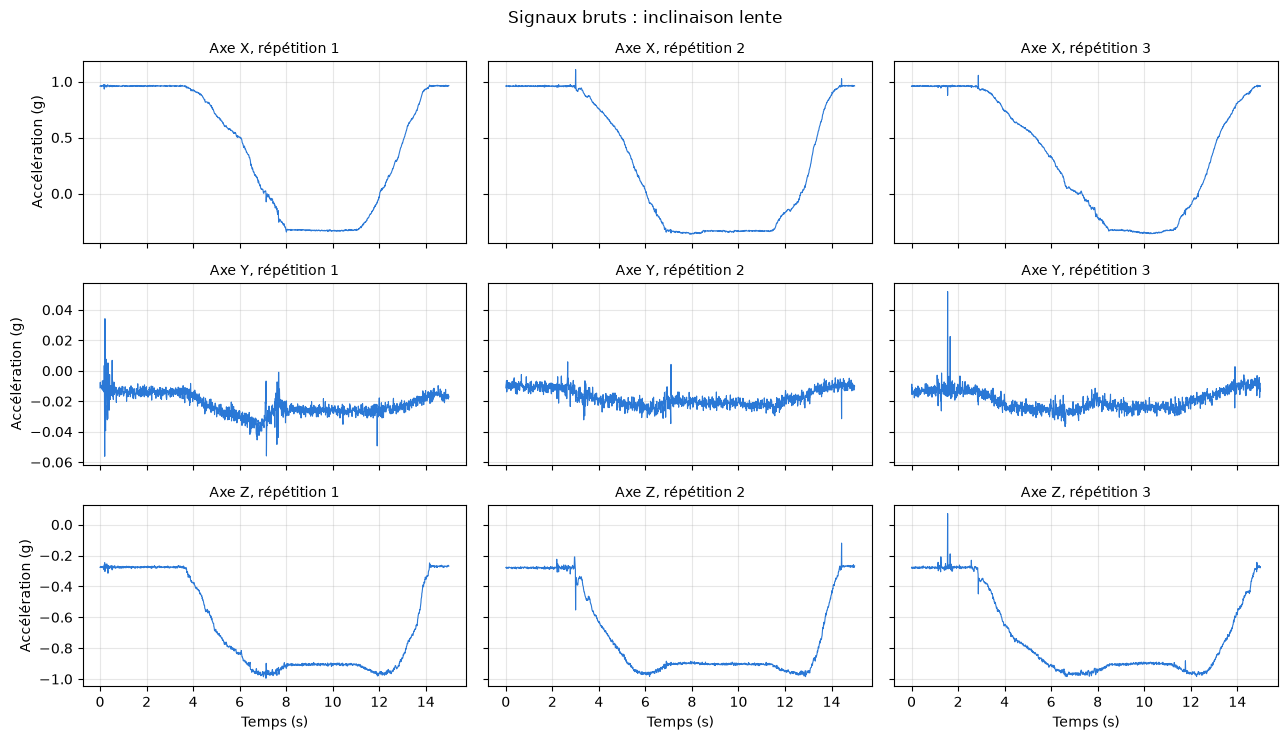

In [73]:
tracer_axes(inclinaison, "Signaux bruts : inclinaison lente", "inclinaison_axes_bruts")

### Interprétation : inclinaison, signaux bruts

1. **Mouvement.** X passe de 0,96 g à environ -0,34 g pendant que Z passe de -0,28 g à -0,90 g : la gravité passe de X à Z. Y reste proche de 0 : la plaque a tourné autour de Y, d'environ 91 à 95°. Z est minimal quand X = 0 (Z pointe alors vers le bas), puis remonte car on a dépassé cette position d'environ 20°.
2. **Perturbations.** Des pics brefs (à-coups) apparaissent surtout au début du mouvement et à l'arrivée en position, par exemple à 3,0 s dans la répétition 2. Ils viennent probablement de la main ou d'un contact de la plaque.
3. **Répétabilité.** Même forme et mêmes valeurs dans les trois répétitions, mais des durées différentes, car le geste est manuel (montée de 4,1 s, 3,8 s et 5,5 s).

## Norme : inclinaison

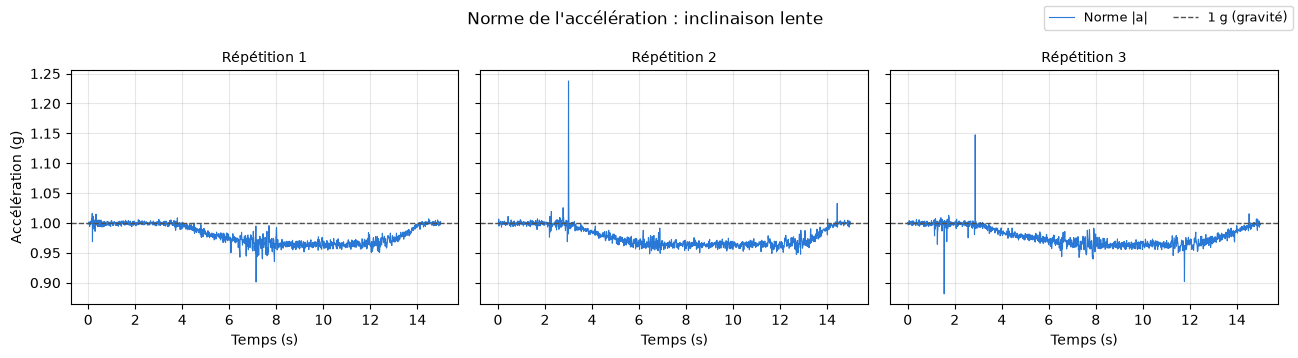

Répétition 1 : moyenne = 0.9803 g, écart-type = 16.44 mg, min = 0.901 g, max = 1.016 g
Répétition 2 : moyenne = 0.9777 g, écart-type = 17.26 mg, min = 0.947 g, max = 1.238 g
Répétition 3 : moyenne = 0.9779 g, écart-type = 16.03 mg, min = 0.881 g, max = 1.148 g


In [74]:
ajouter_norme(inclinaison)
tracer_norme(inclinaison, "Norme de l'accélération : inclinaison lente", "inclinaison_norme_brute")

# Moyenne et écart-type de la norme pour chaque répétition
for rep, df in inclinaison.items():
    print(f"Répétition {rep} : moyenne = {df['norme_g'].mean():.4f} g, "
          f"écart-type = {df['norme_g'].std() * 1000:.2f} mg, "
          f"min = {df['norme_g'].min():.3f} g, max = {df['norme_g'].max():.3f} g")

### Interprétation : inclinaison, norme

1. **Théorie.** Une inclinaison lente change la direction de la gravité par rapport au capteur, pas sa longueur : la norme devrait rester à 1 g.
2. **Mesure.** Elle passe de 1,00 g au départ à environ 0,96 g au maintien. C'est l'effet du décalage de Z (+0,04 g) : avec Z vers le bas, -1 + 0,04 = -0,96 g. Sur le capteur immobile, avec Z vers le haut, le même décalage donnait environ 1,04 g.
3. **À-coups.** Ils se voient comme des pics brefs. Le plus grand est à 3,0 s dans la répétition 2 (1,24 g) : à cet instant, la main ajoute une accélération à la gravité.

## Spectre : inclinaison

Le mouvement est lent : on affiche seulement 0 à 3 Hz (`fmax=3`).

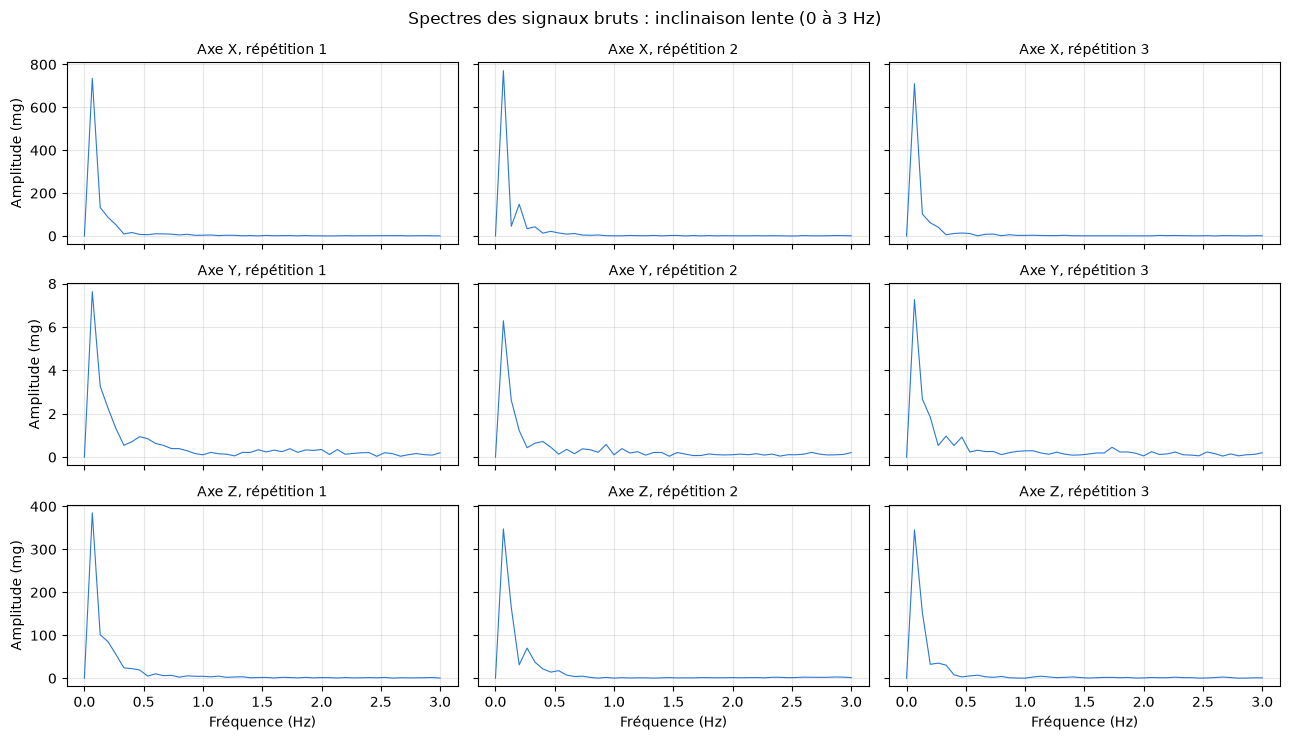

In [75]:
tracer_spectre(inclinaison, "Spectres des signaux bruts : inclinaison lente (0 à 3 Hz)",
               "inclinaison_spectre_brut", fmax=3)

### Interprétation : inclinaison, spectres

1. **Fréquences du mouvement.** Presque tout le mouvement se trouve en dessous de 0,5 Hz environ, avec un pic au premier point du spectre (0,067 Hz) : l'inclinaison est très lente, avec un seul aller-retour en 15 s.
2. **Amplitude selon l'axe.** Le pic est d'environ 700 à 770 mg sur X et 350 à 390 mg sur Z, mais seulement 6 à 8 mg sur Y. La plaque tourne autour de Y : cet axe reste presque horizontal et la gravité ne s'y projette presque pas.
3. **Conséquence pour le filtrage.** Le mouvement est très en dessous des coupures testées (2 et 4 Hz) : un passe-bas le conserve, et réduit le bruit et les à-coups, qui sont plus rapides.

## Moyenne glissante : inclinaison

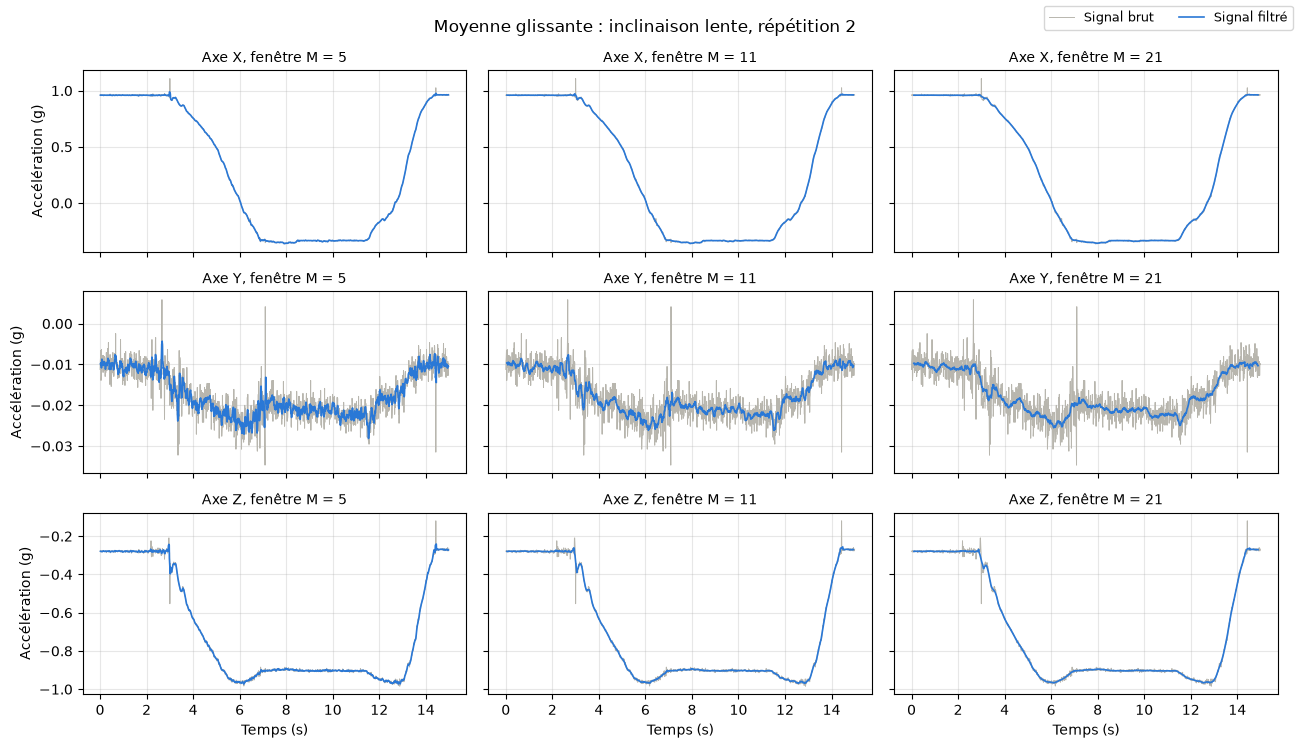

In [76]:
tracer_moyenne_glissante(inclinaison, 2, FENETRES,
                         "Moyenne glissante : inclinaison lente, répétition 2",
                         "inclinaison_rep2_moyenne_glissante")

## Passe-bas de Butterworth : inclinaison

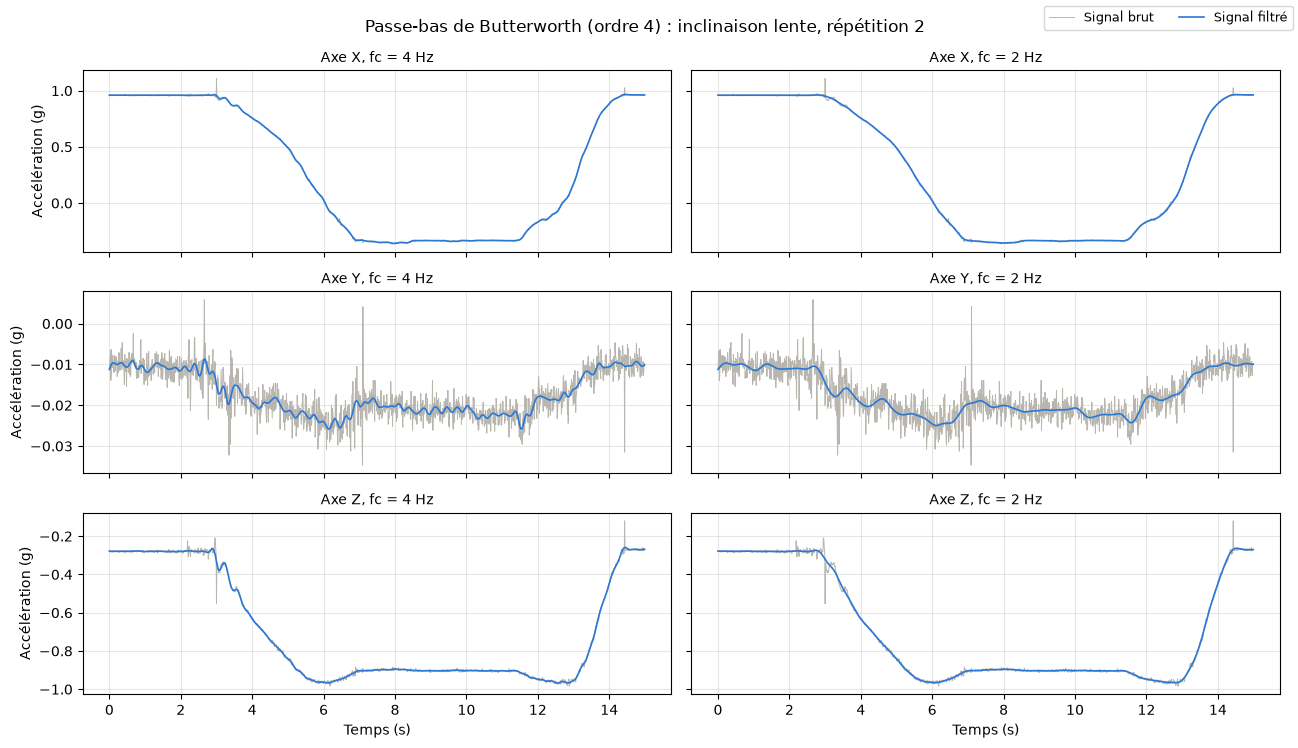

In [77]:
tracer_passe_bas(inclinaison, 2, COUPURES,
                 "Passe-bas de Butterworth (ordre 4) : inclinaison lente, répétition 2",
                 "inclinaison_rep2_passe_bas")

## Comparaison des deux filtres : inclinaison

Écart-type σ, en mg, mesuré pendant le maintien (9 à 11 s), quand le capteur bouge peu.

In [78]:
comparer_filtres(inclinaison, debut=9, fin=11)

,Répétition,Axe,Brut,Moy. glissante M=11,Butterworth fc=4 Hz,Moy. glissante M=21,Butterworth fc=2 Hz
0,1,X,3.36,2.23,2.10,2.10,2.01
1,1,Y,2.22,0.57,0.49,0.44,0.38
2,1,Z,4.32,1.30,1.17,1.01,0.90
3,2,X,3.82,2.64,2.58,2.34,2.32
4,2,Y,2.17,0.94,0.90,0.79,0.75
5,2,Z,3.84,1.21,1.07,0.95,0.88
6,3,X,9.96,9.48,9.52,9.29,9.42
7,3,Y,2.32,0.83,0.79,0.69,0.64
8,3,Z,5.02,3.23,3.20,3.10,3.10


### Interprétation : inclinaison, filtrage

1. **Mouvement conservé.** Avec les deux filtres et tous les réglages testés, la courbe filtrée suit bien le mouvement sur X et Z. C'est cohérent avec le spectre : le mouvement est en dessous de 0,5 Hz, bien en dessous des coupures.
2. **À-coup.** À 3 s (Z, répétition 2), le pic brut va de -0,21 à -0,55 g. Avec un filtrage faible (M = 5, fc = 4 Hz), il reste une petite bosse. Avec fc = 2 Hz, elle disparaît presque.
3. **Bruit et limite.** Pendant le maintien (9 à 11 s), le bruit diminue nettement, par exemple de 3,84 à 1,07 mg sur Z (répétition 2, fc = 4 Hz), et les deux filtres sont proches. Sur X dans la répétition 3, l'écart-type reste d'environ 9,5 mg : la main n'était pas parfaitement fixe et X a varié lentement (de -0,33 à -0,355 g). Cette variation lente est conservée par les filtres.

# Situation 3 — Rotation contrôlée

In [79]:
rotation = charger("rotation")
rotation[1].head()

Répétition 1 : 1500 échantillons, durée = 14.99 s
Répétition 2 : 1500 échantillons, durée = 14.99 s
Répétition 3 : 1500 échantillons, durée = 14.99 s


,t_us,t_s,ax_g,ay_g,az_g
0,567759605,0.000000,0.97827,-0.01001,-0.22559
1,567769603,0.009998,0.97217,-0.00977,-0.22144
2,567779605,0.020000,0.97046,-0.00854,-0.22412
3,567789605,0.030000,0.96924,-0.02173,-0.22192
4,567799605,0.040000,0.98047,-0.01807,-0.23437


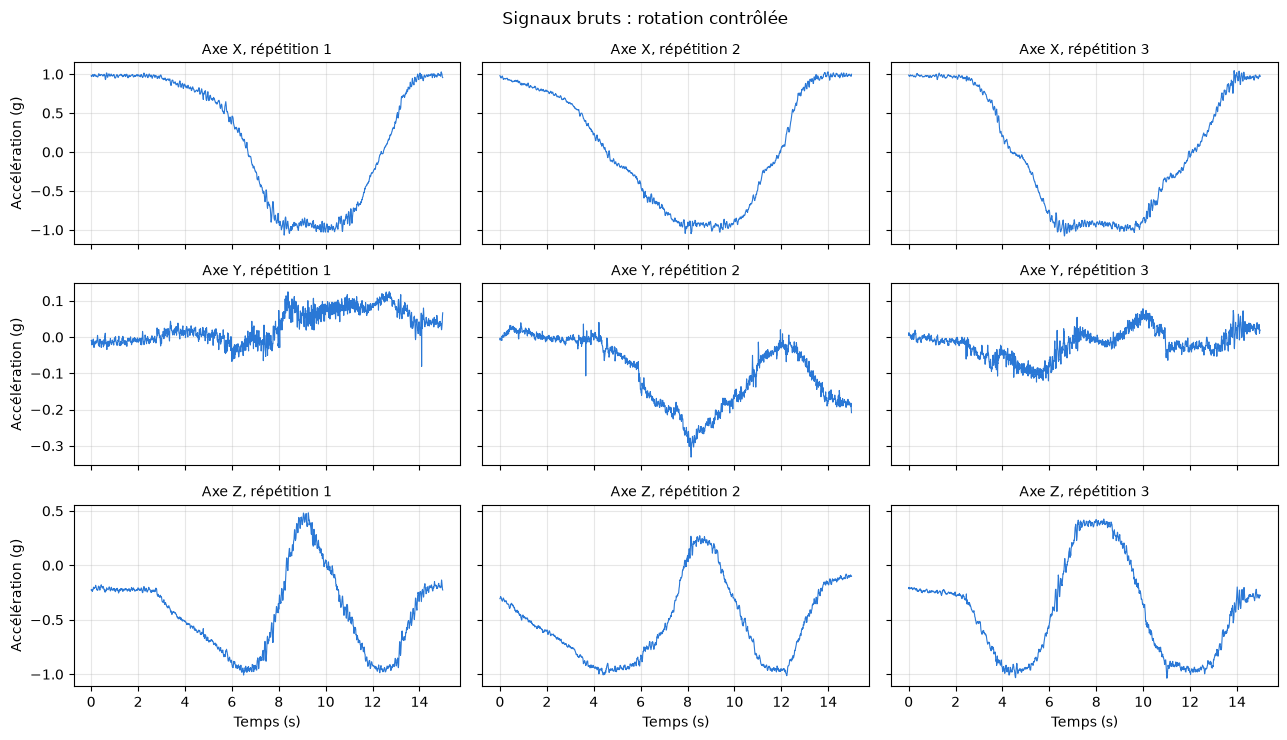

In [80]:
tracer_axes(rotation, "Signaux bruts : rotation contrôlée", "rotation_axes_bruts")

In [ ]:
ajouter_norme(rotation)
tracer_norme(rotation, "Norme de l'accélération : rotation contrôlée", "rotation_norme_brute")

for rep, df in rotation.items():
    print(f"Répétition {rep} : moyenne = {df['norme_g'].mean():.4f} g, "
          f"écart-type = {df['norme_g'].std() * 1000:.2f} mg, "
          f"min = {df['norme_g'].min():.3f} g, max = {df['norme_g'].max():.3f} g")

**Interprétation : signaux bruts et norme (à compléter) :**

## Spectre : rotation

Premier graphique : le mouvement (0 à 2 Hz). Second graphique : les tremblements (2 à 20 Hz), beaucoup plus petits.

In [ ]:
tracer_spectre(rotation, "Spectres des signaux bruts : rotation, mouvement (0 à 2 Hz)",
               "rotation_spectre_mouvement", fmax=2)
tracer_spectre(rotation, "Spectres des signaux bruts : rotation, tremblements (2 à 20 Hz)",
               "rotation_spectre_tremblements", fmin=2, fmax=20)

**Interprétation : spectres (à compléter) :**

## Filtrage : rotation

In [ ]:
tracer_moyenne_glissante(rotation, 3, FENETRES,
                         "Moyenne glissante : rotation contrôlée, répétition 3",
                         "rotation_rep3_moyenne_glissante")

In [ ]:
tracer_passe_bas(rotation, 3, COUPURES,
                 "Passe-bas de Butterworth (ordre 4) : rotation contrôlée, répétition 3",
                 "rotation_rep3_passe_bas")

In [ ]:
comparer_rugosite(rotation)

**Interprétation : filtrage (moyenne glissante, passe-bas et comparaison) (à compléter) :**

## Situation  4 - Oscillations

In [11]:

oscillations = charger_oscillations()
oscillations[1].head()

Répétition 1 : 1500 mesures observées, 0 point(s) interpolé(s), durée 14.99 s
Répétition 2 : 1500 mesures observées, 2 point(s) interpolé(s), durée 15.01 s
Répétition 3 : 1500 mesures observées, 2 point(s) interpolé(s), durée 15.01 s


,t_s,ax_g,ay_g,az_g
0,0.00,1.003420,0.006590,-0.155030
1,0.01,0.991702,-0.003658,-0.147226
2,0.02,1.002440,0.004390,-0.175780
3,0.03,1.003908,0.005620,-0.172608
4,0.04,0.995120,0.005130,-0.163820


## Bloc 1 — Tracer les trois axes

Le mouvement prévu est un glissement aller-retour selon Y. Les axes X et Z devraient surtout porter la gravité et rester relativement stables, sauf si la plaque bascule ou si la main lui transmet des mouvements parasites.

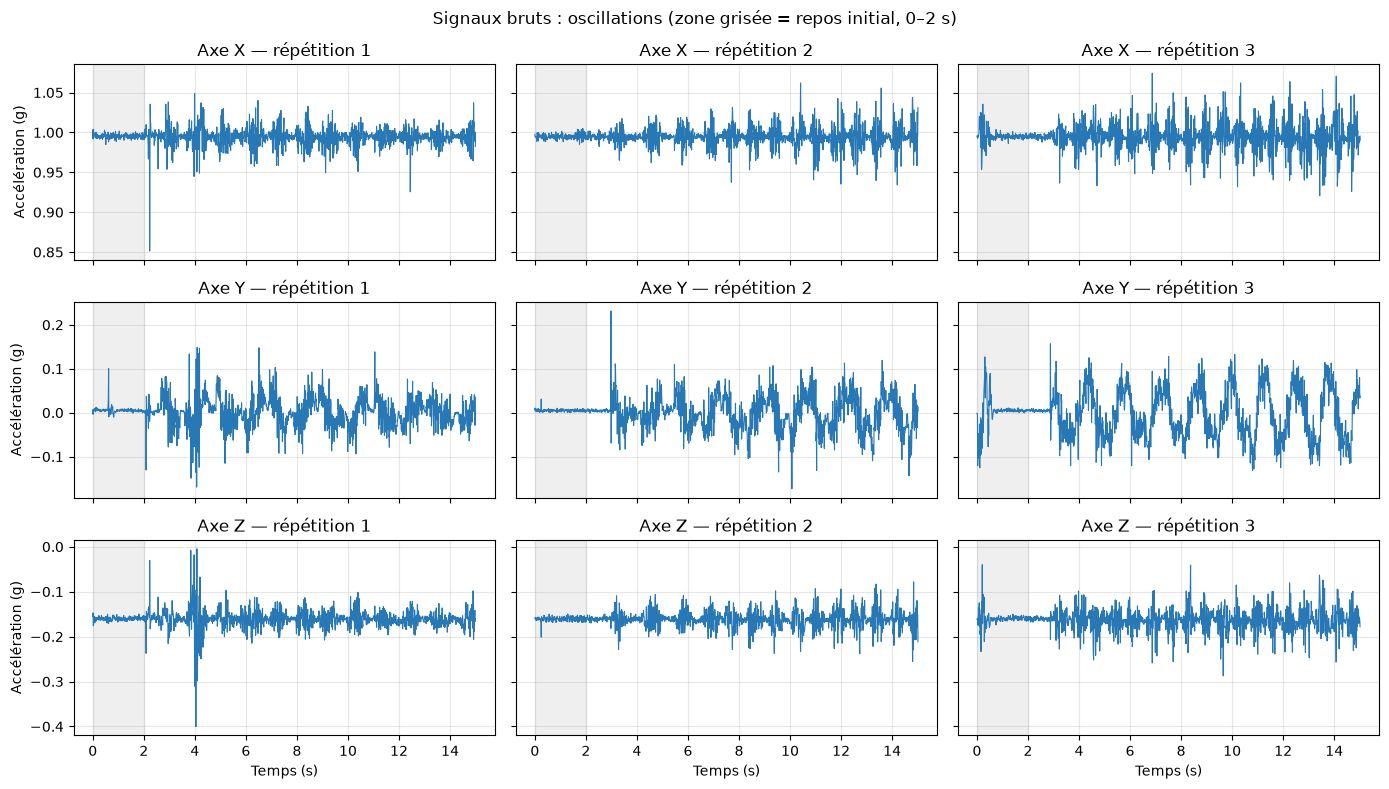

In [12]:
fig, grille = plt.subplots(3, 3, figsize=(14, 8), sharex=True, sharey='row')
for ligne, (col, nom) in enumerate(AXES):
    for j, rep in enumerate((1, 2, 3)):
        df = oscillations[rep]
        grille[ligne, j].plot(df.t_s, df[col], color='#2878b5', lw=0.8)
        grille[ligne, j].axvspan(0, 2, color='grey', alpha=0.12)
        grille[ligne, j].set_title(f'Axe {nom} — répétition {rep}')
        grille[ligne, j].grid(alpha=.3)
for ax in grille[:, 0]: ax.set_ylabel('Accélération (g)')
for ax in grille[-1, :]: ax.set_xlabel('Temps (s)')
fig.suptitle('Signaux bruts : oscillations (zone grisée = repos initial, 0–2 s)')
fig.tight_layout(); fig.savefig(DOSSIER_FIG / 'oscillations_axes_bruts.png', dpi=150); plt.show()

### Interprétation — signaux bruts

Le geste demandé était un va-et-vient sur la table, dans la direction Y, entre deux repères espacés de 3 cm (course visée ±0,5 cm), avec 2 s de repos au début. Le mouvement se voit surtout sur **Y** : son écart-type global est d’environ 32, 36 et 52 mg pour les répétitions 1 à 3. X varie moins (environ 11–17 mg) et Z reste proche de sa composante de gravité négative (moyenne ≈ −0,16 g), avec de petites variations.

Les données ne reproduisent pas exactement le geste prévu : les fondamentales mesurées sont environ 0,48, 0,61 et 0,74 Hz, toutes inférieures à 1 Hz. Les répétitions ne sont donc pas parfaitement régulières ni identiques. Les changements rapides visibles sur le signal brut sont cohérents avec des à-coups de frottement (adhérence puis glissement) et les mouvements manuels. Ils ne prouvent pas à eux seuls un défaut du capteur.

Chaque fichier contient 1 500 points. La répétition 1 a tous ses points; les répétitions 2 et 3 ont chacune deux mesures manquantes, comblées par interpolation pour les analyses qui supposent un pas de temps constant.

## Bloc 2 — Calculer et tracer la norme

La norme combine les trois axes. Pour un capteur soumis seulement à la gravité, elle serait proche de 1 g; pendant une translation, l’accélération du mouvement peut la faire varier.

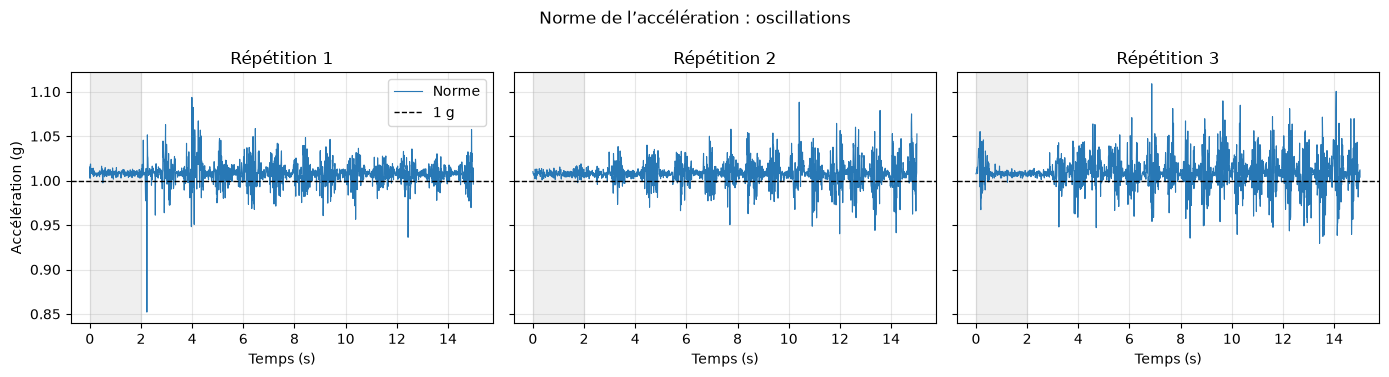

,Répétition,Moyenne norme (g),Écart-type (mg),Min (g),Max (g)
0,1,1.008,12.963,0.852,1.094
1,2,1.008,13.975,0.940,1.088
2,3,1.009,19.406,0.929,1.109


In [14]:
for df in oscillations.values():
    df['norme_g'] = np.sqrt(df.ax_g**2 + df.ay_g**2 + df.az_g**2)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True, sharey=True)
for ax, rep in zip(axes, (1, 2, 3)):
    df = oscillations[rep]
    ax.plot(df.t_s, df.norme_g, color='#2878b5', lw=.8, label='Norme')
    ax.axhline(1, color='black', ls='--', lw=1, label='1 g')
    ax.axvspan(0, 2, color='grey', alpha=.12); ax.set_title(f'Répétition {rep}')
    ax.set_xlabel('Temps (s)'); ax.grid(alpha=.3)
axes[0].set_ylabel('Accélération (g)'); axes[0].legend()
fig.suptitle('Norme de l’accélération : oscillations'); fig.tight_layout()
fig.savefig(DOSSIER_FIG / 'oscillations_norme_brute.png', dpi=150); plt.show()
pd.DataFrame([{'Répétition': r, 'Moyenne norme (g)': d.norme_g.mean(), 'Écart-type (mg)': d.norme_g.std()*1000, 'Min (g)': d.norme_g.min(), 'Max (g)': d.norme_g.max()} for r,d in oscillations.items()]).round(3)

### Interprétation — norme

La norme reste dominée par la gravité, car le capteur n’a pas été retourné pendant le glissement. Elle peut néanmoins s’écarter de 1 g : l’accéléromètre mesure la gravité **et** l’accélération de translation, et ses petits décalages de calibration demeurent présents. Les variations de norme peuvent aussi refléter des à-coups ou un léger basculement de la plaque. La norme est utile comme résumé, mais elle masque la direction du mouvement : l’axe Y doit rester la référence pour étudier ce va-et-vient.

## Bloc 3 — Calculer et tracer le spectre

On étudie la fenêtre active de 2 à 15 s et l’axe Y, qui correspond à la direction du glissement. L

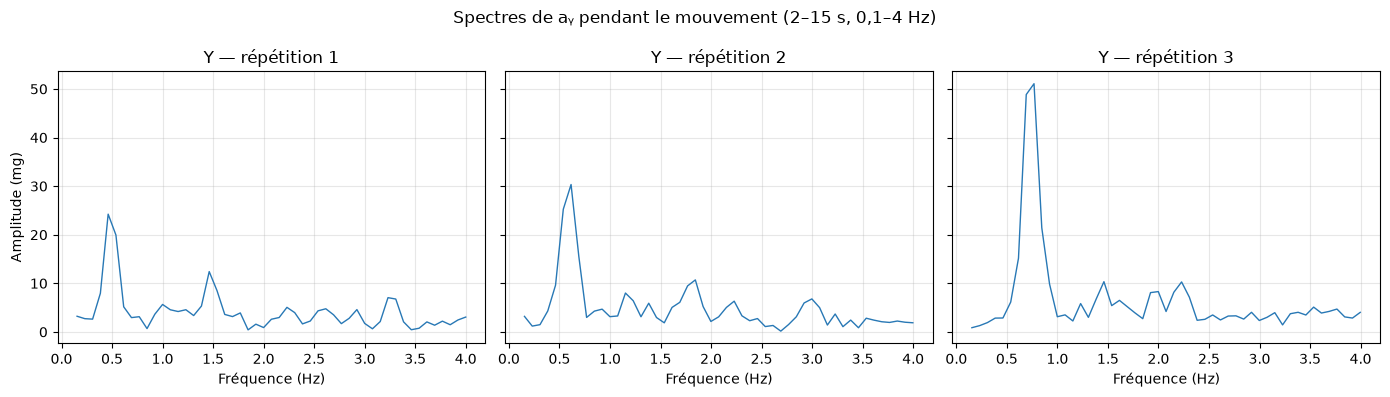

Répétition 1 — principaux pics détectés


,Fréquence (Hz),Amplitude (mg)
0,0.5,24.2
1,1.0,5.7
2,1.5,12.4
3,2.2,5.1
4,2.6,4.8
5,3.2,7.0


Répétition 2 — principaux pics détectés


,Fréquence (Hz),Amplitude (mg)
0,0.6,30.3
1,1.2,8.0
2,1.4,5.9
3,1.8,10.7
4,2.2,6.3
5,3.0,6.8


Répétition 3 — principaux pics détectés


,Fréquence (Hz),Amplitude (mg)
0,0.8,51.1
1,1.2,5.8
2,1.5,10.3
3,2.0,8.3
4,2.2,10.3
5,3.5,5.1


In [15]:
def spectre_actif(df, colonne='ay_g'):
    d = df[(df.t_s >= 2) & (df.t_s <= 15)]
    x = d[colonne].to_numpy(); x = x - x.mean()
    w = np.hanning(len(x))
    f = np.fft.rfftfreq(len(x), d=1/FE_HZ)
    a = 2*np.abs(np.fft.rfft(x*w))/w.sum()
    return f, a

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
pics = {}
for ax, rep in zip(axes, (1, 2, 3)):
    f, a = spectre_actif(oscillations[rep])
    bande = (f >= .1) & (f <= 4)
    ax.plot(f[bande], a[bande]*1000, color='#2878b5', lw=1)
    ax.set_title(f'Y — répétition {rep}'); ax.set_xlabel('Fréquence (Hz)'); ax.grid(alpha=.3)
    peaks, _ = find_peaks(a[bande], prominence=np.max(a[bande])*.025)
    fb, ab = f[bande], a[bande]
    ordre = peaks[np.argsort(ab[peaks])[::-1]][:6]
    pics[rep] = pd.DataFrame({'Fréquence (Hz)': fb[ordre], 'Amplitude (mg)': ab[ordre]*1000}).sort_values('Fréquence (Hz)')
axes[0].set_ylabel('Amplitude (mg)'); fig.suptitle('Spectres de aᵧ pendant le mouvement (2–15 s, 0,1–4 Hz)')
fig.tight_layout(); fig.savefig(DOSSIER_FIG / 'oscillations_spectre_y.png', dpi=150); plt.show()
for rep, tab in pics.items():
    print(f'Répétition {rep} — principaux pics détectés'); display(tab.round(1).reset_index(drop=True))

### Interprétation — spectres

Le contenu fréquentiel confirme que l’essentiel du mouvement mesuré est porté par Y. Les fondamentales estimées dans le suivi des acquisitions sont **0,48 Hz (rep. 1), 0,61 Hz (rep. 2) et 0,74 Hz (rep. 3)** : le va-et-vient réel est plus lent que la cadence visée de 1 Hz. La fréquence de 1 Hz était une consigne, pas une mesure.



## Bloc 4 — Moyenne glissante



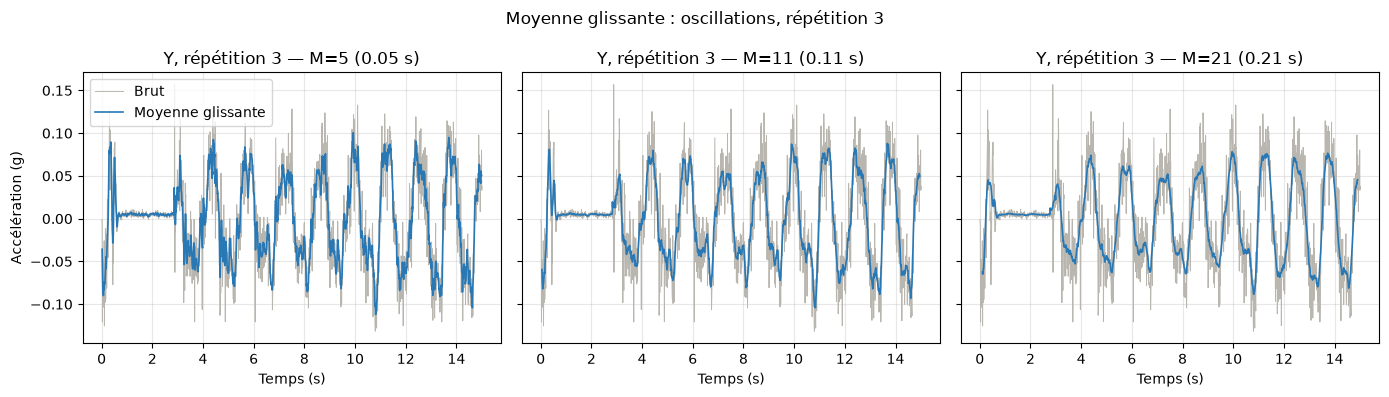

In [16]:
def moyenne_glissante(x, M):
    return pd.Series(x).rolling(window=M, center=True).mean()

fenetres = [5, 11, 21]
df = oscillations[3]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, M in zip(axes, fenetres):
    ax.plot(df.t_s, df.ay_g, color='#b8b6ae', lw=.7, label='Brut')
    ax.plot(df.t_s, moyenne_glissante(df.ay_g, M), color='#2878b5', lw=1.2, label='Moyenne glissante')
    ax.set_title(f'Y, répétition 3 — M={M} ({M/FE_HZ:.2f} s)'); ax.set_xlabel('Temps (s)'); ax.grid(alpha=.3)
axes[0].set_ylabel('Accélération (g)'); axes[0].legend()
fig.suptitle('Moyenne glissante : oscillations, répétition 3'); fig.tight_layout()
fig.savefig(DOSSIER_FIG / 'oscillations_moyenne_glissante.png', dpi=150); plt.show()

In [17]:
# Tableau de dispersion globale, comparable à celui du notebook immobile.
# Ici l'écart-type contient aussi le mouvement : il ne mesure pas le seul bruit.
lignes = []
for rep, d in oscillations.items():
    for col, nom in AXES:
        ligne = {'Répétition': rep, 'Axe': nom, 'Brut (mg)': d[col].std()*1000}
        for M in fenetres:
            ligne[f'Moyenne M={M} (mg)'] = moyenne_glissante(d[col], M).std()*1000
        lignes.append(ligne)
display(pd.DataFrame(lignes).round(2))

,Répétition,Axe,Brut (mg),Moyenne M=5 (mg),Moyenne M=11 (mg),Moyenne M=21 (mg)
0,1,X,11.27,5.12,3.55,2.52
1,1,Y,32.26,22.18,20.25,18.44
2,1,Z,19.77,9.48,7.18,5.34
3,2,X,12.05,5.72,3.91,2.72
4,2,Y,36.34,28.78,27.09,25.15
5,2,Z,17.62,9.16,6.41,4.59
6,3,X,16.97,7.83,5.24,3.72
7,3,Y,52.28,47.20,45.37,42.61
8,3,Z,24.03,13.18,9.03,6.43


### Interprétation — moyenne glissante

La moyenne glissante réduit les variations rapides, mais elle lisse aussi le va-et-vient. Les fenêtres les plus longues atténuent davantage l’amplitude des oscillations et peuvent faire disparaître leurs détails. M = 5 est le compromis le plus prudent pour visualiser le mouvement; M = 11 ou 21 sert surtout à montrer l’effet d’un lissage plus fort. Les valeurs aux bords sont incomplètes parce qu’il manque des voisins pour calculer une fenêtre centrée. Le tableau donne l’écart-type global, qui inclut le mouvement et ne doit pas être présenté comme une mesure du seul bruit.

## Bloc 5 — Passe-bas de Butterworth

On garde l’ordre 4 et les fréquences de coupure 4 et 2 Hz, comme dans l’analyse de référence. Le filtre est appliqué dans les deux sens (`sosfiltfilt`) : il ne décale pas la phase, mais atténue les composantes proches de la coupure.

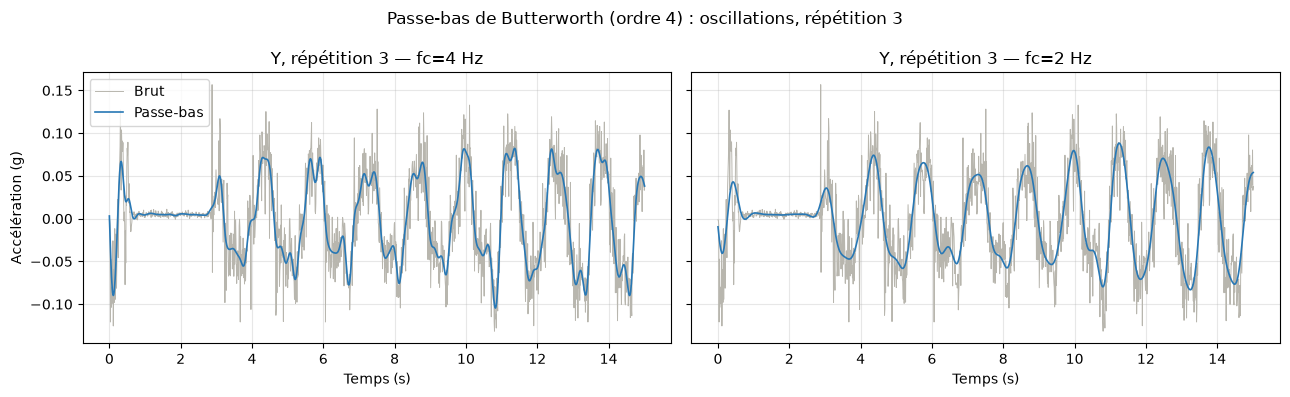

In [18]:
ORDRE = 4
def passe_bas(x, fc):
    sos = butter(ORDRE, fc, btype='lowpass', fs=FE_HZ, output='sos')
    return sosfiltfilt(sos, np.asarray(x))

coupures = [4, 2]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=True)
for ax, fc in zip(axes, coupures):
    ax.plot(df.t_s, df.ay_g, color='#b8b6ae', lw=.7, label='Brut')
    ax.plot(df.t_s, passe_bas(df.ay_g, fc), color='#2878b5', lw=1.2, label='Passe-bas')
    ax.set_title(f'Y, répétition 3 — fc={fc} Hz'); ax.set_xlabel('Temps (s)'); ax.grid(alpha=.3)
axes[0].set_ylabel('Accélération (g)'); axes[0].legend()
fig.suptitle('Passe-bas de Butterworth (ordre 4) : oscillations, répétition 3'); fig.tight_layout()
fig.savefig(DOSSIER_FIG / 'oscillations_passe_bas.png', dpi=150); plt.show()

In [19]:
# Tableau de dispersion globale après chaque coupure (mouvement + bruit).
lignes = []
for rep, d in oscillations.items():
    for col, nom in AXES:
        ligne = {'Répétition': rep, 'Axe': nom, 'Brut (mg)': d[col].std()*1000}
        for fc in coupures:
            ligne[f'Butterworth fc={fc} Hz (mg)'] = np.std(passe_bas(d[col], fc), ddof=1)*1000
        lignes.append(ligne)
display(pd.DataFrame(lignes).round(2))

,Répétition,Axe,Brut (mg),Butterworth fc=4 Hz (mg),Butterworth fc=2 Hz (mg)
0,1,X,11.27,3.34,2.06
1,1,Y,32.26,20.30,18.29
2,1,Z,19.77,6.84,4.64
3,2,X,12.05,3.78,2.60
4,2,Y,36.34,27.16,25.07
5,2,Z,17.62,6.14,4.20
6,3,X,16.97,4.69,3.13
7,3,Y,52.28,45.88,43.57
8,3,Z,24.03,8.16,5.42


### Interprétation — passe-bas

Les coupures à 4 Hz et 2 Hz sont au-dessus des fondamentales observées (0,48–0,74 Hz) : le va-et-vient lent doit rester visible. La coupure à 2 Hz supprime plus de variations rapides dues aux à-coups de frottement, mais peut aussi réduire les harmoniques qui décrivent la forme non sinusoïdale du geste. Pour présenter le rythme général, 2 Hz peut être utile; pour conserver davantage la forme du signal, 4 Hz est plus prudent. Les tableaux donnent l’écart-type global, qui inclut mouvement et bruit; ils décrivent la dispersion, pas le bruit seul. Les extrémités d’un filtre aller-retour peuvent montrer des effets de bord : ne pas les interpréter comme un geste supplémentaire.

## Bloc 6 — Comparer les filtres par la rugosité

Pendant une oscillation, l’écart-type mélange mouvement et bruit. On compare donc aussi la rugosité — l’écart-type des différences entre points consécutifs — sur toute la durée. Cette mesure diminue si le filtre retire les changements rapides; elle ne prouve pas à elle seule que le signal filtré est plus fidèle.

In [21]:
def rugosite(x):
    return np.nanstd(np.diff(np.asarray(x))) * 1000

lignes = []
for rep, d in oscillations.items():
    for col, nom in AXES:
        x = d[col].to_numpy()
        lignes.append({'Répétition': rep, 'Axe': nom, 'Brut (mg)': rugosite(x),
                       'Moyenne M=11 (mg)': rugosite(moyenne_glissante(x, 11)),
                       'Butterworth 4 Hz (mg)': rugosite(passe_bas(x, 4)),
                       'Moyenne M=21 (mg)': rugosite(moyenne_glissante(x, 21)),
                       'Butterworth 2 Hz (mg)': rugosite(passe_bas(x, 2))})
table_rugosite = pd.DataFrame(lignes)
display(table_rugosite.round(2))

,Répétition,Axe,Brut (mg),Moyenne M=11 (mg),Butterworth 4 Hz (mg),Moyenne M=21 (mg),Butterworth 2 Hz (mg)
0,1,X,15.43,1.45,0.50,0.75,0.17
1,1,Y,37.29,3.73,1.75,2.04,0.96
2,1,Z,27.10,2.50,0.94,1.36,0.37
3,2,X,16.74,1.55,0.62,0.81,0.15
4,2,Y,35.77,3.69,2.11,2.16,1.24
5,2,Z,22.81,2.25,0.94,1.20,0.29
6,3,X,23.35,2.13,0.67,1.11,0.19
7,3,Y,34.01,4.36,3.19,2.93,2.26
8,3,Z,30.65,3.08,1.16,1.60,0.37


### Interprétation — comparaison et bilan

Une baisse de rugosité après filtrage signifie que les variations rapides ont diminué. Il faut la lire avec les courbes et les spectres : filtrer trop fort peut rendre le tracé plus lisse tout en effaçant des détails réels du mouvement. Les oscillations lentes restent compatibles avec fc = 2 Hz, mais la forme et les à-coups sont mieux conservés avec fc = 4 Hz.

**Bilan.** La direction mesurée du glissement est Y; les trois essais montrent un mouvement périodique mais manuel, plus lent que la cadence visée et variable d’une répétition à l’autre. Les frottements ajoutent des composantes rapides. La course doit être rapportée comme la mesure à la règle, 3 cm ± 0,5 cm; une course calculée à partir de l’accélération n’est qu’une estimation conditionnelle. Enfin, une double intégration des données brutes n’est pas fiable ici : un petit offset d’accélération s’accumule et produit une grande dérive de position.